# 03 – Baselines

Simple benchmarks that every model must beat (CLAUDE.md section 6, lectures 1 and 5):

| Model | Forecast of the 24 prices of day D |
|---|---|
| `naive_d1` | prices of D−1 at the same hours |
| `naive_d7` | prices of D−7 at the same hours |
| `naive_ref` | D−7 if D is a Monday, Saturday or Sunday, D−1 otherwise |
| `holt_winters` | additive Holt-Winters, weekly seasonality (168 h), no trend, refitted every day on the last 8 weeks |

`naive_ref` is the **reference naive** of the `epftoolbox` convention (Lago et al., 2021): D−1 carries the most recent price level, but it is a poor guide when D and D−1 do not share the same weekly regime (Saturday after a working Friday, Sunday after Saturday, Monday after a weekend). Its MAE is the denominator of the **rMAE** of every model.

Each model is run with the common rolling loop (`src.evaluation.run_rolling`) on the main test period and on the control period. The baselines only read past prices from `history` (up to D−1 23:00) and, for the reference naive, the day of week of D. They return no quantiles (empty `q10` … `q90` columns). Forecasts are cached in `results/` and `results/control/`.

Section 1 covers the naives, section 2 the additive Holt-Winters model.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg
from src.baselines import HoltWinters, NaiveD1, NaiveD7, NaiveReference
from src.data import load_dataset, split_for_day
from src.evaluation import mae, rmse, run_rolling

df = load_dataset()
CONTROL_DAYS = pd.date_range(cfg.CONTROL_START, cfg.CONTROL_END, freq="D")

print(f"Dataset: {df.index[0]} → {df.index[-1]}")
print(f"Main test: {len(cfg.TEST_DAYS)} days, control: {len(CONTROL_DAYS)} days ({CONTROL_DAYS[0].date()} → {CONTROL_DAYS[-1].date()})")

Dataset: 2023-01-01 00:00:00 → 2026-11-08 23:00:00
Main test: 183 days, control: 24 days (2026-10-16 → 2026-11-08)


## 1. Naive forecasts

### 1.1 Check on one week

First week of the main test (Wednesday 1 April → Tuesday 7 April 2026): the three naives against the actual prices. `naive_ref` follows `naive_d7` on Saturday, Sunday and Monday and `naive_d1` on the other days.

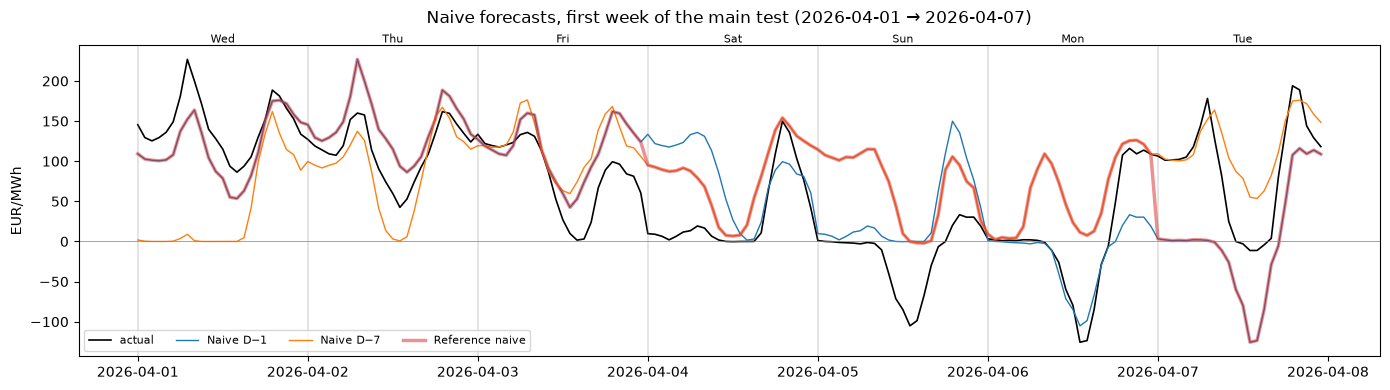

In [2]:
naives = {"naive_d1": NaiveD1(), "naive_d7": NaiveD7(), "naive_ref": NaiveReference()}
labels = {"naive_d1": "Naive D−1", "naive_d7": "Naive D−7", "naive_ref": "Reference naive"}
colors = {"naive_d1": "C0", "naive_d7": "C1", "naive_ref": "C3"}

week = cfg.TEST_DAYS[:7]
fig, ax = plt.subplots(figsize=(14, 4))
actual = df.loc[week[0] : week[-1] + pd.Timedelta(hours=23), cfg.TARGET]
ax.plot(actual.index, actual, color="k", lw=1.2, label="actual")
for name, model in naives.items():
    forecasts = []
    for day in week:
        history, future_cov = split_for_day(df, day)
        y_pred, _ = model.predict(history, future_cov)
        forecasts.append(pd.Series(y_pred, index=future_cov.index))
    forecast = pd.concat(forecasts)
    ax.plot(forecast.index, forecast, color=colors[name], lw=2.5 if name == "naive_ref" else 1,
            alpha=0.5 if name == "naive_ref" else 1, label=labels[name])
for day in week:
    ax.axvline(day, color="grey", lw=0.3)
    ax.text(day + pd.Timedelta(hours=12), 1.0, day.strftime("%a"), transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=8)
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("EUR/MWh")
ax.set_title(f"Naive forecasts, first week of the main test ({week[0].date()} → {week[-1].date()})", pad=16)
ax.legend(fontsize=8, ncol=4, loc="lower left")
fig.tight_layout()
plt.show()

### 1.2 Rolling evaluation

One forecast per day D, moving forward one day at a time. Each call only receives `split_for_day(df, D)`.

In [3]:
res = {name: run_rolling(model, name, df, cfg.TEST_DAYS) for name, model in naives.items()}

naive_d1: loaded from results/naive_d1.parquet
naive_d7: loaded from results/naive_d7.parquet
naive_ref: loaded from results/naive_ref.parquet


In [4]:
res_control = {
    name: run_rolling(model, name, df, CONTROL_DAYS, results_dir=cfg.RESULTS_DIR / "control")
    for name, model in naives.items()
}

naive_d1: loaded from results/control/naive_d1.parquet
naive_d7: loaded from results/control/naive_d7.parquet
naive_ref: loaded from results/control/naive_ref.parquet


### 1.3 Results

MAE and RMSE in EUR/MWh, and rMAE (MAE / MAE of `naive_ref` on the same days). The naives have no quantiles, so no pinball loss. Diebold-Mariano tests and the comparison with the other models are in `06_results.ipynb`.

In [5]:
def summary(results: dict) -> pd.DataFrame:
    ref_mae = mae(results["naive_ref"]["y_true"], results["naive_ref"]["y_pred"])
    return pd.DataFrame({
        name: {
            "MAE": mae(r["y_true"], r["y_pred"]),
            "rMAE": mae(r["y_true"], r["y_pred"]) / ref_mae,
            "RMSE": rmse(r["y_true"], r["y_pred"]),
            "days": r["target_date"].nunique(),
        }
        for name, r in results.items()
    }).T.astype({"days": int})

table = pd.concat({"main test": summary(res), "control": summary(res_control)})
table.round(3)

MAE   rMAE     RMSE  days
main test naive_d1   33.040  0.943   53.696   183
          naive_d7   41.695  1.190   65.075   183
          naive_ref  35.049  1.000   56.978   183
control   naive_d1   39.491  0.539   56.869    24
          naive_d7   89.309  1.219  115.193    24
          naive_ref  73.293  1.000  102.684    24

In [6]:
ref_main = table.loc[("main test", "naive_ref"), "MAE"]
ref_control = table.loc[("control", "naive_ref"), "MAE"]
print(f"Reference naive MAE (rMAE denominator): main test {ref_main:.2f} EUR/MWh, control {ref_control:.2f} EUR/MWh")

Reference naive MAE (rMAE denominator): main test 35.05 EUR/MWh, control 73.29 EUR/MWh


**Reference naive MAE: 35.05 EUR/MWh on the main test, 73.29 EUR/MWh on the control period.** These are the rMAE denominators of every model.

- On the main test, `naive_d1` (33.0) is slightly better than the reference naive (35.0), and `naive_d7` is the worst (41.7). The reference convention is kept as the protocol fixes it: rMAE < 1 means "better than the standard EPF naive", not "better than the best naive".
- The reference forecasts are identical to `epftoolbox.evaluation.naive_forecast(prices, m=None)` on all 4,392 + 576 hours (checked once, 2026-11-19, in the throwaway environment used for the Diebold-Mariano check).
- The control period is short (24 days, 11 of them forecast with D−7) and turbulent at the end of October: on the weekends of 24–25 October and 31 October – 1 November, D−7 is off by 140 to 240 EUR/MWh on average over the day. The reference MAE more than doubles while `naive_d1` only goes from 33 to 39. The rMAE level on the control period is therefore not comparable with the main test; for the contamination test, compare models with each other on the same period (e.g. the ranking, or the ratio of a foundation model's MAE to SARIMAX's).

### 1.4 Error by day of week and by hour

The reference naive takes, for each day of week, the lag that is expected to work best. The table below checks it on the main test: MAE of D−1 and D−7 by day of week of D.

In [7]:
def mae_by(results: dict, key) -> pd.DataFrame:
    return pd.DataFrame({
        name: r.assign(err=(r["y_true"] - r["y_pred"]).abs()).groupby(key(r))["err"].mean()
        for name, r in results.items()
    })

by_dow = mae_by(res, lambda r: r["target_date"].dt.day_of_week)
by_dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow["days"] = res["naive_ref"].groupby(res["naive_ref"]["target_date"].dt.day_of_week)["target_date"].nunique().to_numpy()
by_dow.round(2)

,naive_d1,naive_d7,naive_ref,days
Mon,50.59,50.71,50.71,26
Tue,33.90,39.60,33.90,26
Wed,22.58,36.87,22.58,27
Thu,29.01,38.17,29.01,26
Fri,26.72,43.80,26.72,26
Sat,44.12,40.38,40.38,26
Sun,24.77,42.51,42.51,26


On the main test (April–September), D−7 only helps on Saturday (40.4 vs 44.1 EUR/MWh); on Monday both lags are equal, and on Sunday D−1 (the Saturday) is much better than D−7 (24.8 vs 42.5): in spring and summer, Saturday and Sunday share the same low-demand, high-solar regime. Monday is the hardest day for both lags.

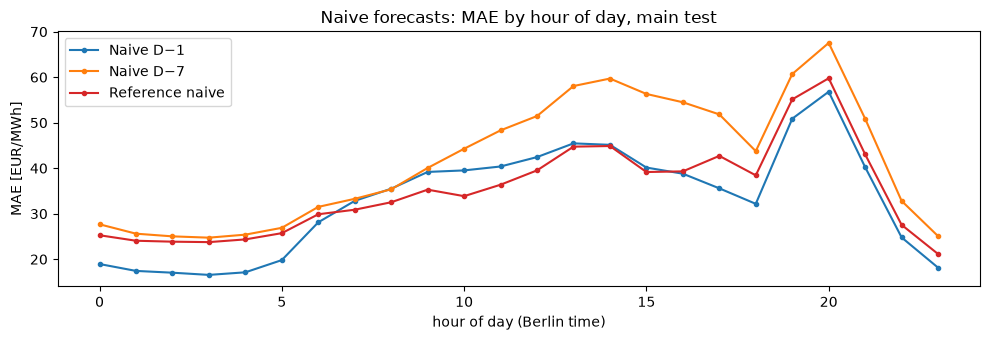

In [8]:
by_hour = mae_by(res, lambda r: r["hour"])
ax = by_hour.rename(columns=labels).plot(figsize=(10, 3.5), marker="o", ms=3, color=[colors[c] for c in by_hour])
ax.set_xlabel("hour of day (Berlin time)")
ax.set_ylabel("MAE [EUR/MWh]")
ax.set_title("Naive forecasts: MAE by hour of day, main test")
plt.tight_layout()
plt.show()

## 2. Additive Holt-Winters

Holt-Winters smoothing (lecture 5) without trend, with a **weekly** season of p = 168 h, which contains the daily cycle and the weekday/weekend difference. For each day D, the model is refitted on the last 8 weeks of prices (1,344 h, i.e. 8 seasons) and forecasts the 24 hours of D:

$$
\begin{aligned}
L_n &= \alpha\,(y_n - S_{n-p}) + (1-\alpha)\,L_{n-1} \\
S_n &= \gamma\,(y_n - L_n) + (1-\gamma)\,S_{n-p} \\
\hat y_{n+i} &= L_n + S_{n+i-p}, \qquad i = 1,\dots,24
\end{aligned}
$$

No trend: over a 24 h horizon, a trend fitted on 8 weeks would mostly extrapolate noise. This is a supplementary model (CLAUDE.md section 6); it only uses past prices, no covariates.

### 2.1 Additive, not multiplicative

Multiplicative seasonality, $\hat y_{n+i} = L_n \, S_{n+i-p}$, scales the seasonal pattern with the level and divides by the seasonal factor in its updates ($L_n = \alpha\, y_n / S_{n-p} + \dots$). It needs strictly positive data: with zero or negative prices, the factors lose their meaning (a negative factor flips the sign of the whole pattern) and the updates divide by values close to 0. DE-LU prices are often zero or negative on sunny, windy days:

In [9]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

periods = {
    "pre-test": (cfg.PRETEST_START, cfg.PRETEST_END),
    "main test": (cfg.TEST_START, cfg.TEST_END),
    "control": (cfg.CONTROL_START, cfg.CONTROL_END),
}
nonpositive = pd.DataFrame({
    name: {"hours": len(p), "hours ≤ 0": int((p <= 0).sum()), "share ≤ 0 [%]": 100 * (p <= 0).mean(), "min [EUR/MWh]": p.min()}
    for name, (start, end) in periods.items()
    for p in [df.loc[start : end + pd.Timedelta(hours=23), cfg.TARGET]]
}).T
display(nonpositive.round(1))

all_days = cfg.TEST_DAYS.append(CONTROL_DAYS)
windows_with_nonpositive = sum(
    (split_for_day(df, day)[0][cfg.TARGET].iloc[-cfg.FIT_WINDOW_HOURS:] <= 0).any() for day in all_days
)
print(f"Fit windows (8 weeks before D) containing a price ≤ 0: {windows_with_nonpositive} of {len(all_days)} days")

window = split_for_day(df, cfg.TEST_DAYS[0])[0][cfg.TARGET].iloc[-cfg.FIT_WINDOW_HOURS:]
try:
    ExponentialSmoothing(window, seasonal="mul", seasonal_periods=cfg.HW_SEASON)
except ValueError as e:
    print(f"statsmodels, multiplicative seasonality: ValueError: {e}")

,hours,hours ≤ 0,share ≤ 0 [%],min [EUR/MWh]
pre-test,28464.0,1547.0,5.4,-500.0
main test,4392.0,435.0,9.9,-499.0
control,576.0,10.0,1.7,-0.0


Fit windows (8 weeks before D) containing a price ≤ 0: 207 of 207 days
statsmodels, multiplicative seasonality: ValueError: endog must be strictly positive when usingmultiplicative trend or seasonal components.


Every fit window of the main test and of the control period contains zero or negative prices, so the multiplicative form is not even defined (`statsmodels` refuses it). The additive form treats the seasonal pattern as an offset in EUR/MWh, which stays valid on both sides of 0.

### 2.2 Estimation

`statsmodels.tsa.holtwinters.ExponentialSmoothing(trend=None, seasonal="add", seasonal_periods=168)` with its default settings: α, γ, the initial level and the 168 initial seasonal values are estimated jointly by least squares on the one-step-ahead (1 h) errors of the window (`initialization_method="estimated"`).

One setting is changed: the evaluation budget of the L-BFGS-B optimizer (`maxfun`, 15,000 by default). With 170 parameters and numerical gradients (≈ 170 evaluations per gradient), the default budget stops the optimizer after about 85 iterations, before convergence. It is an optimizer setting, not a model hyperparameter: raising it only lets the default estimator reach its least-squares solution. Comparison on the first day of the main test:

In [10]:
import warnings

hw = HoltWinters()
history, future_cov = split_for_day(df, cfg.TEST_DAYS[0])
window = history[cfg.TARGET].iloc[-hw.window:]
actual = df.loc[future_cov.index, cfg.TARGET].to_numpy()

model = ExponentialSmoothing(window, trend=None, seasonal="add", seasonal_periods=cfg.HW_SEASON)
fits, caught = {}, {}
for name, fit in [("default budget", model.fit), (f"maxfun = {hw.maxfun:,}", lambda: hw.fit(history))]:
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        fits[name] = fit()
    caught[name] = ", ".join(type(x.message).__name__ for x in w) or "none"
pd.DataFrame({
    name: {
        "optimizer message": r.mle_retvals.message,
        "warning": caught[name],
        "evaluations": r.mle_retvals.nfev,
        "alpha": r.params["smoothing_level"],
        "gamma": r.params["smoothing_seasonal"],
        "SSE (fit window)": r.sse,
        "MAE on D [EUR/MWh]": mae(actual, r.forecast(cfg.HORIZON)),
    }
    for name, r in fits.items()
})

,default budget,"maxfun = 1,000,000"
optimizer message,"STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT",CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
warning,ConvergenceWarning,none
evaluations,15136,120400
alpha,1.0,1.0
gamma,0.0,0.0
SSE (fit window),188521.912933,188348.686393
MAE on D [EUR/MWh],20.432317,21.115926


The default budget ends with a `ConvergenceWarning`; with the larger budget, the optimizer stops on its convergence criterion. The in-sample SSE barely changes, but the 24 forecasts differ by a few EUR/MWh, so the converged fit is used. A fit takes 1–2 s here, about 4 minutes for the 207 days.

### 2.3 Estimated parameters

To look at the fitted parameters, the model is refitted on one day per week of the main test (the forecasts themselves come from the daily refits of section 2.5).

In [11]:
sample_days = cfg.TEST_DAYS[::7]
params = pd.DataFrame([
    {
        "day": day.date(),
        "alpha": r.params["smoothing_level"],
        "gamma": r.params["smoothing_seasonal"],
        "converged": bool(r.mle_retvals.success),
    }
    for day in sample_days
    for r in [hw.fit(split_for_day(df, day)[0])]
]).set_index("day")
print(f"{len(params)} fits, all converged: {params['converged'].all()}")
params[["alpha", "gamma"]].describe().loc[["min", "50%", "max"]].round(4)

27 fits, all converged: True


,alpha,gamma
min,1.0,0.0
50%,1.0,0.0
max,1.0,0.0


On every sampled day, **α = 1 and γ = 0**, both on the bounds of [0, 1]. The recursions then reduce to

$$
L_n = y_n - S_{n-p}, \qquad S_n = S_{n-p} = s_{k(n)}, \qquad \hat y_{n+i} = y_n + s_{k(n+i)} - s_{k(n)},
$$

where $s_k$ ($k$ = hour of the week) is the initial seasonal profile estimated on the window. The forecast of D is the **last observed price** (D−1 23:00) shifted by the change of a **fixed weekly profile**, the average shape of the last 8 weeks:

- α = 1: hourly prices are so persistent that the best predictor of the next hour, which is what least squares on one-step-ahead errors rewards, is the last value. The criterion optimizes 1 h ahead forecasts, while the task asks for 1 to 24 h ahead.
- γ = 0: the seasonal profile is not updated within the window; it is re-estimated every day through the initial values, so it still follows the window.

The model therefore behaves like a "last price + average weekly shape" forecast, which is between the naives (one past day copied as is) and a seasonal model.

### 2.4 Check on one week

Same week as in section 1.1, Holt-Winters against the reference naive.

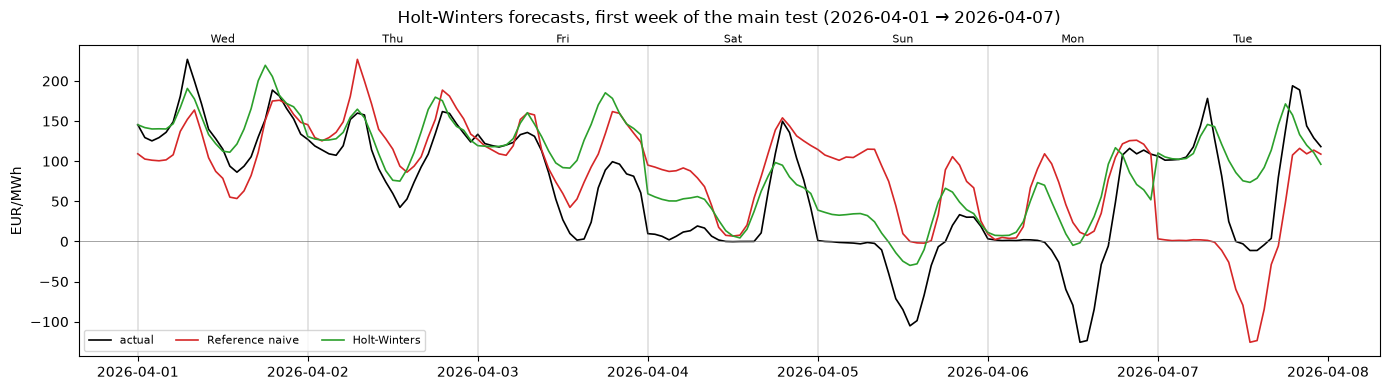

In [12]:
fig, ax = plt.subplots(figsize=(14, 4))
actual = df.loc[week[0] : week[-1] + pd.Timedelta(hours=23), cfg.TARGET]
ax.plot(actual.index, actual, color="k", lw=1.2, label="actual")
for name, model, color in [("naive_ref", naives["naive_ref"], colors["naive_ref"]), ("holt_winters", hw, "C2")]:
    forecasts = []
    for day in week:
        history, future_cov = split_for_day(df, day)
        y_pred, _ = model.predict(history, future_cov)
        forecasts.append(pd.Series(y_pred, index=future_cov.index))
    forecast = pd.concat(forecasts)
    ax.plot(forecast.index, forecast, color=color, lw=1.2, label={"naive_ref": "Reference naive", "holt_winters": "Holt-Winters"}[name])
for day in week:
    ax.axvline(day, color="grey", lw=0.3)
    ax.text(day + pd.Timedelta(hours=12), 1.0, day.strftime("%a"), transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=8)
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("EUR/MWh")
ax.set_title(f"Holt-Winters forecasts, first week of the main test ({week[0].date()} → {week[-1].date()})", pad=16)
ax.legend(fontsize=8, ncol=3, loc="lower left")
fig.tight_layout()
plt.show()

### 2.5 Rolling evaluation

One refit per day D, on the main test and on the control period. Forecasts are cached in `results/holt_winters.parquet` and `results/control/holt_winters.parquet`.

In [13]:
res["holt_winters"] = run_rolling(hw, "holt_winters", df, cfg.TEST_DAYS)
res_control["holt_winters"] = run_rolling(hw, "holt_winters", df, CONTROL_DAYS, results_dir=cfg.RESULTS_DIR / "control")

holt_winters: loaded from results/holt_winters.parquet
holt_winters: loaded from results/control/holt_winters.parquet


### 2.6 Results

Same metrics as in section 1.3; rMAE is still relative to `naive_ref`.

In [14]:
table = pd.concat({"main test": summary(res), "control": summary(res_control)})
table.round(3)

MAE   rMAE     RMSE  days
main test naive_d1      33.040  0.943   53.696   183
          naive_d7      41.695  1.190   65.075   183
          naive_ref     35.049  1.000   56.978   183
          holt_winters  28.153  0.803   45.037   183
control   naive_d1      39.491  0.539   56.869    24
          naive_d7      89.309  1.219  115.193    24
          naive_ref     73.293  1.000  102.684    24
          holt_winters  43.339  0.591   59.134    24

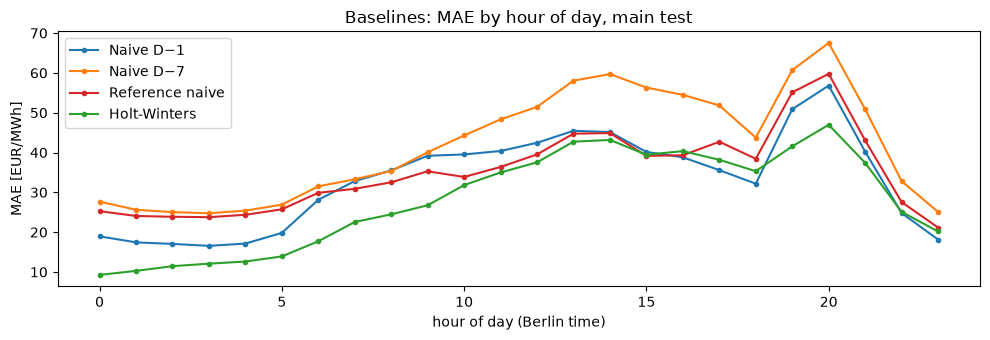

,naive_d1,naive_d7,naive_ref,holt_winters
Mon,50.59,50.71,50.71,29.87
Tue,33.90,39.60,33.90,27.76
Wed,22.58,36.87,22.58,26.68
Thu,29.01,38.17,29.01,29.90
Fri,26.72,43.80,26.72,30.66
Sat,44.12,40.38,40.38,24.69
Sun,24.77,42.51,42.51,27.57


In [15]:
labels["holt_winters"], colors["holt_winters"] = "Holt-Winters", "C2"
by_hour = mae_by(res, lambda r: r["hour"])
ax = by_hour.rename(columns=labels).plot(figsize=(10, 3.5), marker="o", ms=3, color=[colors[c] for c in by_hour])
ax.set_xlabel("hour of day (Berlin time)")
ax.set_ylabel("MAE [EUR/MWh]")
ax.set_title("Baselines: MAE by hour of day, main test")
plt.tight_layout()
plt.show()

by_dow = mae_by(res, lambda r: r["target_date"].dt.day_of_week)
by_dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow.round(2)

**Holt-Winters: MAE 28.2 EUR/MWh on the main test (rMAE 0.80), the best baseline.** It beats all naives on the main test (−20 % MAE, −21 % RMSE vs `naive_ref`).

- **By hour**: the error grows with the distance to the last observation. At night, the forecast starts from D−1 23:00 and the MAE is 9–14 EUR/MWh (vs 17–26 for the naives); from 13:00 to 18:00, the anchor is too far away and Holt-Winters is no better than the naives. It is clearly better at the evening peak (19:00–20:00), where the 8-week average profile is more reliable than a single past day.
- **By day of week**: the weekly profile handles the regime changes that the naives miss. On Monday, the MAE falls from 50.7 (`naive_ref`) to 29.9, on Saturday from 40.4 to 24.7. On Wednesday to Friday, D−1 is a good guide and `naive_d1` is slightly better.
- **Negative prices**: the average profile smooths the midday solar dip. Holt-Winters forecasts a price ≤ 0 for 170 hours, against 435 actual ones, and its MAE on these hours (50.2) is worse than the naives' (≈ 42–43). Seeing these hours coming needs the solar and wind forecasts of D, which this model does not use.
- **Control period**: rMAE 0.59, behind `naive_d1` (0.54). On 24 turbulent days this is not conclusive; as for the naives, the control rMAE level is not comparable with the main test.

The Diebold-Mariano tests against the other models are in `06_results.ipynb`.